## Imports

In [ ]:
# #For colab
# from LLMArchitecture import LLM
# import tiktoken
# import numpy
# from DatasetDataLoader import LLMdataloader
# from Textgeneration import generate_text_simple, text_to_token_ids, token_ids_to_text

#For Local
from llmfromscratch.LLMArchitecture import LLM
import tiktoken
import numpy
from llmfromscratch.DatasetDataLoader import LLMdataloader
from llmfromscratch.Textgeneration import generate_text_simple, text_to_token_ids, token_ids_to_text

import torch
import numpy as np
import random
import tiktoken
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

## Setup

In [2]:
#Setting the seed
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

#CONGIGURATION
CONFIG = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 384,        # Embedding dimension
    "n_heads": 6,         # Number of attention heads
    "n_layers": 6,        # Number of layers
    "drop_rate": 0.2,      # Dropout rate
    "qkv_bias": False,      # Query-key-value bias
    "Epoches": 10,
    "lr": 3e-4,
    "batch_size": 8,
    "eval_freq": 50
}

#Tokenizer
tokenizer = tiktoken.get_encoding("gpt2")

In [3]:
#setting the device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Loading the data

In [ ]:
#Loading the data for local
with open("D:/Projects/LLMFromScratch/data/input.txt", "r", encoding="utf-8") as f:
    text_data = f.read()
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))
print("Characters:", total_characters)
print("Tokens:", total_tokens)

In [ ]:
# #Loading the data for colab
# with open("input.txt", "r", encoding="utf-8") as f:
#     text_data = f.read()
# total_characters = len(text_data)
# total_tokens = len(tokenizer.encode(text_data))
# print("Characters:", total_characters)
# print("Tokens:", total_tokens)

Characters: 1115394
Tokens: 338025


In [6]:
#Train?val split
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

#Train and val loader
train_loader = LLMdataloader(
    train_data,
    batch_size=CONFIG["batch_size"],
    max_length=CONFIG["context_length"],
    stride=CONFIG["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = LLMdataloader(
    val_data,
    batch_size=CONFIG["batch_size"],
    max_length=CONFIG["context_length"],
    stride=CONFIG["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

train_tokens = 0
for input_batch, target_batch in train_loader:
    train_tokens += input_batch.numel()

val_tokens = 0
for input_batch, target_batch in val_loader:
    val_tokens += input_batch.numel()

print("Training tokens:", train_tokens)
print("Validation tokens:", val_tokens)
print("All tokens:", train_tokens + val_tokens)

Training tokens: 301056
Validation tokens: 35840
All tokens: 336896


In [7]:
#Setting the eval_iter to the CONFIG
CONFIG["eval_iter"] = len(val_loader)
CONFIG["eval_iter"]

18

## Utility Functions

In [8]:
#function to calculate loss
def calculate_loss(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)

    logits = model(input_batch)

    loss = torch.nn.functional.cross_entropy(
        logits.flatten(0, 1),
        target_batch.flatten()
    )

    return loss

def calculate_avg_loss(data_loader, model, device, num_batches=None):
    total_loss = 0.

    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calculate_loss(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break

    return total_loss / num_batches

#Function to evaluate the model
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calculate_avg_loss(train_loader, model, device, num_batches=eval_iter)
        val_loss = calculate_avg_loss(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss

#Function to generate text
def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))  # Compact print format
    model.train()

## Training

In [ ]:
#Training function
def train(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    # Initialize lists to track losses and tokens seen
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1
    best_val = float("inf")

    #training loop
    for epoch in range(num_epochs):
        model.train()  # Set model to training mode

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() # Reset loss gradients from previous batch iteration
            loss = calculate_loss(input_batch, target_batch, model, device)
            loss.backward() # Calculate loss gradients
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0) # Gradient clipping to prevent exploding gradients
            optimizer.step() # Update model weights using loss gradients
            tokens_seen += input_batch.numel()
            global_step += 1

            # Optional evaluation step
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # Print a sample text after each epoch
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

        print("==============================================================================================================================================================================")
    return train_losses, val_losses, track_tokens_seen

In [10]:
print(device)

cuda


In [ ]:
model = LLM(CONFIG)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=0.1)

print("Training Starts......")
train_losses, val_losses, tokens_seen = train(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=CONFIG["Epoches"], eval_freq=CONFIG["eval_freq"], eval_iter=CONFIG["eval_iter"],
    start_context="First Citizen:", tokenizer=tokenizer
)
print("Training Finished.....")

# #Saving the trained model for colab
# print("Saving the model.............")
# torch.save({
#     "model_state_dict": model.state_dict(),
#     "optimizer_state_dict": optimizer.state_dict(),
# }, r"final_pretrained_model.pth")
# print("Model saved...............")


#Saving the trained model for local
print("Saving the model.............")
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
}, r"D:\Projects\LLMFromScratch\models\final_pretrained_model.pth")
print("Model saved...............")

Training Starts......
Ep 1 (Step 000000): Train loss 10.527, Val loss 10.536
Ep 1 (Step 000050): Train loss 6.202, Val loss 6.237
Ep 1 (Step 000100): Train loss 5.856, Val loss 6.021
First Citizen:    IUS: IUS:   IUS:  IUS:  IUS:  IUS: IUS:  IUS: IUS:   IUS
Ep 2 (Step 000150): Train loss 5.491, Val loss 5.811
Ep 2 (Step 000200): Train loss 5.185, Val loss 5.668
Ep 2 (Step 000250): Train loss 4.959, Val loss 5.516
First Citizen:    And, And I am I'll be a man, And I'll not, And I'll be a man, And I am I'll not, And I'll be a man, And I'll
Ep 3 (Step 000300): Train loss 4.919, Val loss 5.436
Ep 3 (Step 000350): Train loss 4.766, Val loss 5.426
Ep 3 (Step 000400): Train loss 4.700, Val loss 5.275
First Citizen: And I am a man, And I have been And I have been a man, And I have been And I have been And, And I am a man, And I am a man, And I
Ep 4 (Step 000450): Train loss 4.591, Val loss 5.239
Ep 4 (Step 000500): Train loss 4.523, Val loss 5.221
Ep 4 (Step 000550): Train loss 4.334, Val loss

## Loss Plottings

In [12]:
#Function to plot losses
def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  # only show integer labels on x-axis

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(tokens_seen, train_losses, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig("loss-plot.pdf")
    plt.show()

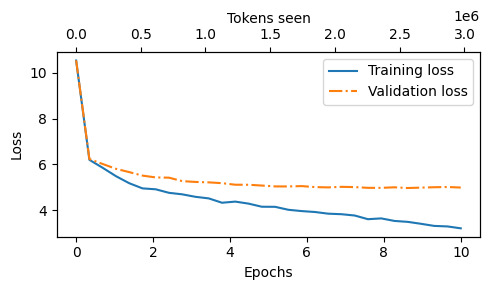

In [13]:
epochs_tensor = torch.linspace(0, CONFIG["Epoches"], len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)